# Bước 3. Khai phá luật kết hợp

Đầu vào: bảng mức đơn hàng `orders_from_dw.csv`, trích từ kho dữ liệu (view `v_orders` trên BigQuery).

In [ ]:
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

In [17]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', 80)

## 1. Đọc dữ liệu và chia tập huấn luyện / kiểm tra

In [19]:
orders = pd.read_csv('/content/drive/MyDrive/Master_UEH_MIS/semester 01/04. Khai phá dữ liệu nâng cao/Đồ án/data/orders_from_dw.csv')
print(orders.shape)
orders.head()

(4922, 12)


,order_id,order_date,segment,region,ship_mode,n_lines,n_subcats,has_furniture,has_office_supplies,has_technology,sub_categories,order_sales
0,CA-2015-100006,2015-09-07,Consumer,East,Standard Class,1,1,0,0,1,Phones,377.970
1,CA-2015-100090,2015-07-08,Corporate,West,Standard Class,2,2,1,1,0,Binders|Tables,699.192
2,CA-2015-100293,2015-03-14,Home Office,South,Standard Class,1,1,0,1,0,Paper,91.056
3,CA-2015-100328,2015-01-28,Consumer,East,Standard Class,1,1,0,1,0,Binders,3.928
4,CA-2015-100363,2015-04-08,Corporate,West,Standard Class,2,2,0,1,0,Fasteners|Paper,21.376


Mỗi dòng là một đơn hàng. Cột `sub_categories` liệt kê các Sub-Category trong đơn, ngăn cách bởi dấu `|`.

Chia 80% huấn luyện (train), 20% kiểm tra (test). Luật kết hợp **chỉ được khai phá trên tập train**

In [20]:
from sklearn.model_selection import train_test_split

train, test = train_test_split(orders, test_size=0.2, random_state=42,
                               stratify=orders['order_sales'] > orders['order_sales'].median())
train = train.copy()
test = test.copy()

# Nhãn đơn giá trị cao: ngưỡng = trung vị giá trị đơn của tập train
nguong = train['order_sales'].median()
train['high_value'] = (train['order_sales'] > nguong).astype(int)
test['high_value'] = (test['order_sales'] > nguong).astype(int)

print('Ngưỡng (trung vị tập train):', nguong)
print('Số đơn train:', len(train), '| test:', len(test))
print('Tỷ lệ đơn giá trị cao - train:', round(train['high_value'].mean(), 3), '| test:', round(test['high_value'].mean(), 3))

Ngưỡng (trung vị tập train): 151.93
Số đơn train: 3937 | test: 985
Tỷ lệ đơn giá trị cao - train: 0.5 | test: 0.499


## 2. Phương pháp 1: Apriori trên giỏ Sub-Category (luật một chiều)

In [21]:
def gio_hang(df):
    gio = []
    for _, don in df.iterrows():
        items = don['sub_categories'].split('|')
        items.append('HV=' + str(don['high_value']))
        gio.append(items)
    return gio

gio_pp1 = gio_hang(train)
gio_pp1[:5]

[['Chairs', 'HV=1'],
 ['Accessories', 'Appliances', 'Binders', 'Envelopes', 'HV=1'],
 ['Phones', 'HV=1'],
 ['Appliances', 'HV=0'],
 ['Furnishings', 'Paper', 'Storage', 'HV=0']]

In [22]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

def khai_pha(gio, min_support=0.01, min_confidence=0.5):
    # Mã hóa giỏ hàng thành bảng True/False (mỗi cột là một item)
    te = TransactionEncoder()
    bang = pd.DataFrame(te.fit(gio).transform(gio), columns=te.columns_)

    # Tìm tập mục phổ biến và sinh luật
    tap_pho_bien = apriori(bang, min_support=min_support, use_colnames=True, max_len=4)
    luat = association_rules(tap_pho_bien, metric='confidence', min_threshold=min_confidence)

    # Chỉ giữ luật có vế phải là nhãn HV, vế trái không chứa nhãn
    vp_la_nhan = luat['consequents'].apply(lambda c: len(c) == 1 and list(c)[0].startswith('HV='))
    vt_khong_nhan = luat['antecedents'].apply(lambda a: not any(x.startswith('HV=') for x in a))
    luat = luat[vp_la_nhan & vt_khong_nhan]
    return tap_pho_bien, luat

tap_pp1, luat_pp1 = khai_pha(gio_pp1)
print('Số tập mục phổ biến:', len(tap_pp1))
print('Số luật có vế phải là nhãn:', len(luat_pp1))
luat_pp1.sort_values('lift', ascending=False)[['antecedents', 'consequents', 'antecedent support', 'support', 'confidence', 'lift']].head(10)

Số tập mục phổ biến: 145
Số luật có vế phải là nhãn: 62


,antecedents,consequents,antecedent support,support,confidence,lift
6,(Copiers),(HV=1),0.012954,0.012954,1.000000,2.000508
49,"(Chairs, Storage)",(HV=1),0.017018,0.017018,1.000000,2.000508
61,"(Binders, Paper, Storage)",(HV=1),0.010414,0.010414,1.000000,2.000508
48,"(Chairs, Phones)",(HV=1),0.016510,0.016510,1.000000,2.000508
59,"(Tables, Phones)",(HV=1),0.010414,0.010414,1.000000,2.000508
57,"(Paper, Tables)",(HV=1),0.011176,0.011176,1.000000,2.000508
45,"(Binders, Tables)",(HV=1),0.013970,0.013716,0.981818,1.964135
21,"(Chairs, Accessories)",(HV=1),0.012954,0.012700,0.980392,1.961282
60,"(Binders, Furnishings, Storage)",(HV=1),0.010668,0.010414,0.976190,1.952877
47,"(Paper, Chairs)",(HV=1),0.023622,0.022860,0.967742,1.935976


## 3. Phương pháp 2: luật kết hợp đa chiều (hybrid-dimension)

In [23]:
def gio_hang_da_chieu(df):
    gio = []
    for _, don in df.iterrows():
        items = don['sub_categories'].split('|')
        items += ['Segment=' + don['segment'], 'Region=' + don['region'], 'ShipMode=' + don['ship_mode']]
        items.append('HV=' + str(don['high_value']))
        gio.append(items)
    return gio

gio_pp2 = gio_hang_da_chieu(train)
gio_pp2[:3]

[['Chairs',
  'Segment=Home Office',
  'Region=West',
  'ShipMode=First Class',
  'HV=1'],
 ['Accessories',
  'Appliances',
  'Binders',
  'Envelopes',
  'Segment=Corporate',
  'Region=South',
  'ShipMode=Same Day',
  'HV=1'],
 ['Phones',
  'Segment=Consumer',
  'Region=East',
  'ShipMode=Standard Class',
  'HV=1']]

In [24]:
tap_pp2, luat_pp2 = khai_pha(gio_pp2)

# Giữ luật có vế trái chứa ít nhất một chiều (Segment / Region / ShipMode)
co_chieu = luat_pp2['antecedents'].apply(lambda a: any(x.startswith(('Segment=', 'Region=', 'ShipMode=')) for x in a))
luat_pp2 = luat_pp2[co_chieu]

print('Số tập mục phổ biến:', len(tap_pp2))
print('Số luật có vế phải là nhãn và vế trái có chiều:', len(luat_pp2))
luat_pp2.sort_values('lift', ascending=False)[['antecedents', 'consequents', 'antecedent support', 'support', 'confidence', 'lift']].head(10)

Số tập mục phổ biến: 1156
Số luật có vế phải là nhãn và vế trái có chiều: 344


,antecedents,consequents,antecedent support,support,confidence,lift
546,"(Segment=Consumer, Furnishings, Accessories)",(HV=1),0.010668,0.010668,1.000000,2.000508
456,"(Segment=Home Office, Tables)",(HV=1),0.010414,0.010414,1.000000,2.000508
770,"(Chairs, Segment=Corporate, Region=West)",(HV=1),0.013208,0.012954,0.980769,1.962037
556,"(ShipMode=Standard Class, Accessories, Phones)",(HV=1),0.012446,0.012192,0.979592,1.959681
459,"(ShipMode=Second Class, Tables)",(HV=1),0.011430,0.011176,0.977778,1.956052
237,"(Region=Central, Bookcases)",(HV=1),0.010922,0.010668,0.976744,1.953985
755,"(Segment=Consumer, Paper, Chairs)",(HV=1),0.012446,0.011938,0.959184,1.918855
439,"(Region=West, Tables)",(HV=1),0.023622,0.022606,0.956989,1.914465
752,"(ShipMode=Standard Class, Furnishings, Chairs)",(HV=1),0.011684,0.011176,0.956522,1.913530
927,"(Segment=Consumer, Storage, Phones)",(HV=1),0.011684,0.011176,0.956522,1.913530


## 4. Chọn 3 luật cho mỗi phương pháp

Tiêu chí chọn (giống nhau cho hai phương pháp):
- **Độ phủ của vế trái ≥ 5%** (`antecedent support`).
- **Confidence ≥ 0,7**.
- Xếp theo **lift** giảm dần, chọn lần lượt.
- **Không trùng sản phẩm**: luật được chọn sau không chứa Sub-Category đã có trong luật trước, để 3 luật bổ sung thông tin cho nhau.

In [25]:
CHIEU = ('Segment=', 'Region=', 'ShipMode=')

def chon_3_luat(luat):
    ung_vien = luat[(luat['antecedent support'] >= 0.05) & (luat['confidence'] >= 0.7)]
    ung_vien = ung_vien.sort_values('lift', ascending=False)

    da_chon, sp_da_dung = [], set()
    for _, l in ung_vien.iterrows():
        san_pham = {x for x in l['antecedents'] if not x.startswith(CHIEU)}
        if san_pham & sp_da_dung:
            continue
        da_chon.append(l)
        sp_da_dung |= san_pham
        if len(da_chon) == 3:
            break
    return pd.DataFrame(da_chon).reset_index(drop=True)

chon_pp1 = chon_3_luat(luat_pp1)
chon_pp2 = chon_3_luat(luat_pp2)

cot = ['antecedents', 'consequents', 'antecedent support', 'support', 'confidence', 'lift']
print('Phương pháp 1:')
display(chon_pp1[cot])
print('Phương pháp 2:')
display(chon_pp2[cot])

Phương pháp 1:


,antecedents,consequents,antecedent support,support,confidence,lift
0,(Tables),(HV=1),0.063246,0.060198,0.951807,1.904098
1,(Chairs),(HV=1),0.112776,0.103886,0.921171,1.842810
2,(Phones),(HV=1),0.162560,0.132334,0.814063,1.628539


Phương pháp 2:


,antecedents,consequents,antecedent support,support,confidence,lift
0,"(Segment=Consumer, Chairs)",(HV=1),0.058420,0.053340,0.913043,1.826551
1,"(Region=West, Phones)",(HV=1),0.052578,0.043942,0.835749,1.671922
2,"(ShipMode=Standard Class, Storage)",(HV=1),0.091948,0.066548,0.723757,1.447882


## 5. So sánh hai phương pháp bằng độ phủ

Một đơn được **phủ** bởi một luật nếu đơn đó chứa đủ các mục ở vế trái của luật. Với mỗi phương pháp, tính:
- độ phủ của từng luật (tỷ lệ đơn thỏa vế trái),
- **độ phủ của cả 3 luật**: tỷ lệ đơn thỏa ít nhất một trong 3 luật.

Tính trên cả tập train (nơi khai phá luật) và tập test (dữ liệu mới).

In [26]:
def tap_muc(don, da_chieu):
    items = set(don['sub_categories'].split('|'))
    if da_chieu:
        items |= {'Segment=' + don['segment'], 'Region=' + don['region'], 'ShipMode=' + don['ship_mode']}
    return items

def thoa_luat(df, luat, da_chieu):
    # Bảng 0/1: mỗi cột là một luật, 1 nếu đơn thỏa vế trái của luật
    ket_qua = pd.DataFrame(index=df.index)
    for i, l in luat.iterrows():
        ket_qua[f'luat_{i+1}'] = df.apply(lambda don: int(l['antecedents'] <= tap_muc(don, da_chieu)), axis=1)
    return ket_qua

bang_do_phu = []
for ten, luat, da_chieu in [('PP1: Apriori một chiều', chon_pp1, False), ('PP2: Đa chiều', chon_pp2, True)]:
    for tap, df in [('train', train), ('test', test)]:
        thoa = thoa_luat(df, luat, da_chieu)
        dong = {'Phương pháp': ten, 'Tập': tap}
        for c in thoa.columns:
            dong['Độ phủ ' + c] = thoa[c].mean()
        dong['Độ phủ cả 3 luật'] = thoa.max(axis=1).mean()
        bang_do_phu.append(dong)

bang_do_phu = pd.DataFrame(bang_do_phu)
bang_do_phu

,Phương pháp,Tập,Độ phủ luat_1,Độ phủ luat_2,Độ phủ luat_3,Độ phủ cả 3 luật
0,PP1: Apriori một chiều,train,0.063246,0.112776,0.162560,0.306833
1,PP1: Apriori một chiều,test,0.053807,0.123858,0.165482,0.305584
2,PP2: Đa chiều,train,0.058420,0.052578,0.091948,0.191516
3,PP2: Đa chiều,test,0.068020,0.046701,0.096447,0.190863


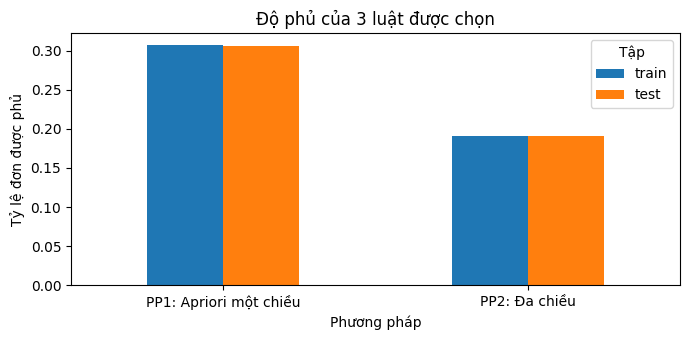

In [27]:
ve = bang_do_phu.pivot(index='Phương pháp', columns='Tập', values='Độ phủ cả 3 luật')
ve[['train', 'test']].plot(kind='bar', rot=0, figsize=(7, 3.5), title='Độ phủ của 3 luật được chọn')
plt.ylabel('Tỷ lệ đơn được phủ')
plt.tight_layout()

## 6. Tạo 3 đặc trưng từ luật và tách thành 3 bộ dữ liệu

Mỗi luật được chọn thành một cột 0/1: bằng 1 nếu đơn thỏa **vế trái** của luật. Không dùng vế phải (nhãn) để tạo đặc trưng, tránh rò rỉ nhãn.


| Bộ | File | Thuộc tính |
|---|---|---|
| A. Gốc (không dùng luật) | `dataset_A_baseline.csv` | 4 thuộc tính cơ bản |
| B. Gốc + luật phương pháp 1 | `dataset_B_pp1.csv` | 4 thuộc tính cơ bản + `AR1`, `AR2`, `AR3` |
| C. Gốc + luật phương pháp 2 | `dataset_C_pp2.csv` | 4 thuộc tính cơ bản + `MD1`, `MD2`, `MD3` |

Mỗi bộ có thêm cột `order_id`, `tap` (train/test) và nhãn `high_value`.

In [28]:
du_lieu = pd.concat([train.assign(tap='train'), test.assign(tap='test')])

dac_trung_pp1 = thoa_luat(du_lieu, chon_pp1, da_chieu=False)
dac_trung_pp1.columns = ['AR1', 'AR2', 'AR3']
dac_trung_pp2 = thoa_luat(du_lieu, chon_pp2, da_chieu=True)
dac_trung_pp2.columns = ['MD1', 'MD2', 'MD3']

co_ban = ['n_subcats', 'has_furniture', 'has_technology', 'has_office_supplies']   # chọn ở bước 1
khoa = ['order_id', 'tap']
nhan = ['high_value']

bo_A = du_lieu[khoa + co_ban + nhan]
bo_B = pd.concat([du_lieu[khoa + co_ban], dac_trung_pp1, du_lieu[nhan]], axis=1)
bo_C = pd.concat([du_lieu[khoa + co_ban], dac_trung_pp2, du_lieu[nhan]], axis=1)

print('Bộ A:', bo_A.shape, '| Bộ B:', bo_B.shape, '| Bộ C:', bo_C.shape)
bo_B.head()

Bộ A: (4922, 7) | Bộ B: (4922, 10) | Bộ C: (4922, 10)


,order_id,tap,n_subcats,has_furniture,has_technology,has_office_supplies,AR1,AR2,AR3,high_value
2323,CA-2017-143609,train,1,1,0,0,0,1,0,1
3951,CA-2018-161046,train,4,0,1,1,0,0,0,1
4838,US-2018-146906,train,1,0,1,0,0,0,1,1
2837,CA-2018-103765,train,1,0,0,1,0,0,0,0
4338,US-2016-130519,train,3,1,0,1,0,0,0,0


In [29]:
bo_A.to_csv('/content/drive/MyDrive/Master_UEH_MIS/semester 01/04. Khai phá dữ liệu nâng cao/Đồ án/data/dataset_A_baseline.csv', index=False)
bo_B.to_csv('/content/drive/MyDrive/Master_UEH_MIS/semester 01/04. Khai phá dữ liệu nâng cao/Đồ án/data/dataset_B_pp1.csv', index=False)
bo_C.to_csv('/content/drive/MyDrive/Master_UEH_MIS/semester 01/04. Khai phá dữ liệu nâng cao/Đồ án/data/dataset_C_pp2.csv', index=False)
print('Đã lưu 3 bộ dữ liệu')

Đã lưu 3 bộ dữ liệu


Bảng tổng hợp 6 luật đã chọn và đặc trưng tương ứng:

In [30]:
luat_da_chon = pd.concat([chon_pp1.assign(phuong_phap='PP1', dac_trung=['AR1', 'AR2', 'AR3']),
                          chon_pp2.assign(phuong_phap='PP2', dac_trung=['MD1', 'MD2', 'MD3'])])
luat_da_chon['antecedents'] = luat_da_chon['antecedents'].apply(lambda a: ', '.join(sorted(a)))
luat_da_chon['consequents'] = luat_da_chon['consequents'].apply(lambda c: ', '.join(c))
luat_da_chon[['phuong_phap', 'dac_trung'] + cot]

,phuong_phap,dac_trung,antecedents,consequents,antecedent support,support,confidence,lift
0,PP1,AR1,Tables,HV=1,0.063246,0.060198,0.951807,1.904098
1,PP1,AR2,Chairs,HV=1,0.112776,0.103886,0.921171,1.842810
2,PP1,AR3,Phones,HV=1,0.162560,0.132334,0.814063,1.628539
0,PP2,MD1,"Chairs, Segment=Consumer",HV=1,0.058420,0.053340,0.913043,1.826551
1,PP2,MD2,"Phones, Region=West",HV=1,0.052578,0.043942,0.835749,1.671922
2,PP2,MD3,"ShipMode=Standard Class, Storage",HV=1,0.091948,0.066548,0.723757,1.447882
